# COGS 109 Checkpoint 2 | Member 1: Thomas Ton | Forward stepwise selection
**Question:** Which pre-draft measurements predict whether a player scores above the median NBA PPG (5.65) in their first three post-combine seasons?

**My method:** Forward stepwise selection. Riley Ramos uses elastic net logistic regression and Ishaan Tibdewal uses lasso logistic regression.

Everyone uses the same data, train/test split, binary outcome, 5 CV folds and 24 candidate predictors. Only the selection method is different.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, roc_auc_score,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay)

os.makedirs('reports', exist_ok=True)

## Step 1: Load the data and make the binary outcome

In [2]:
features = pd.read_csv('../data/predraft_features.csv')
outcomes = pd.read_csv('../data/nba_outcomes.csv')

# same sample as Checkpoint 1: players matched to NCAA stats
df = features.merge(outcomes[['player_id', 'ppg_3yr']], on='player_id')
df = df[df.ncaa_match_status == 'matched'].reset_index(drop=True)
print('n =', len(df))

n = 770


In [3]:
# same 80/20 split as Checkpoint 1
train_idx, test_idx = train_test_split(df.index, test_size=0.20, random_state=42,
                                       stratify=df.position_group)
train = df.loc[train_idx].copy()
test = df.loc[test_idx].copy()
print('Train:', len(train), '| Test:', len(test))

Train: 616 | Test: 154


No natural cutoff exists for NBA PPG, so we use the training median. This splits the classes 50/50.

In [4]:
# 1 = scored more than the training median, 0 = at or below it
threshold = train.ppg_3yr.median()
y_train = (train.ppg_3yr > threshold).astype(int).values
y_test = (test.ppg_3yr > threshold).astype(int).values

print('Threshold:', round(threshold, 2), 'PPG')
print('Proportion of 1s in train:', round(y_train.mean(), 3))
print('Proportion of 1s in test:', round(y_test.mean(), 3))

Threshold: 5.65 PPG
Proportion of 1s in train: 0.5
Proportion of 1s in test: 0.5


## Step 2: Candidate predictors and CV folds
- 10 combine measurements and 11 NCAA stats (quantitative).
- `skipped_drills`: 1 if the player has no agility, sprint or vertical result. Top prospects often skip the drills, so filling those blanks with the median would hide this.
- Position: 2 dummies, baseline Guard.
- That is 24 predictors with n = 616 training players. IDs, names, team and years are left out.
- CV error = proportion of validation players misclassified (0.5 cutoff), averaged over 5 folds.

In [5]:
combine = ['height_in', 'weight_lb', 'wingspan_in', 'standing_reach_in', 'vertical_max_in',
           'vertical_standing_in', 'sprint_sec', 'agility_sec', 'bench_reps', 'body_fat_pct']
ncaa = ['ncaa_games', 'ncaa_mpg', 'ncaa_ppg', 'ncaa_apg', 'ncaa_rpg', 'ncaa_spg', 'ncaa_bpg',
        'ncaa_tov_pg', 'ncaa_fg_pct', 'ncaa_3p_pct', 'ncaa_ft_pct']

for d in [train, test]:
    # position dummies (baseline = Guard)
    d['pos_Forward'] = (d.position_group == 'Forward').astype(int)
    d['pos_Center'] = (d.position_group == 'Center').astype(int)
    # 1 = skipped the athletic drills (no agility, sprint or vertical result)
    drills = d[['agility_sec', 'sprint_sec', 'vertical_max_in']]
    d['skipped_drills'] = drills.isna().all(axis=1).astype(int)

predictors = combine + ncaa + ['skipped_drills', 'pos_Forward', 'pos_Center']
print('Number of predictors:', len(predictors))

# fill missing values with the TRAINING median (never look at the test set)
X_train = train[predictors].reset_index(drop=True)
X_test = test[predictors].reset_index(drop=True)
for col in predictors:
    median = X_train[col].median()
    X_train[col] = X_train[col].fillna(median)
    X_test[col] = X_test[col].fillna(median)

skipped = X_train.skipped_drills == 1
print('Proportion of 1s | skipped drills:', round(y_train[skipped].mean(), 2),
      '| did drills:', round(y_train[~skipped].mean(), 2))

Number of predictors: 24
Proportion of 1s | skipped drills: 0.65 | did drills: 0.47


In [6]:
# 5 folds of the training set, the same for everyone
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(X_train, y_train))


def cv_error(model, cols):
    # misclassification rate on each validation fold, then the average and its standard error
    errors = []
    for fit_idx, val_idx in folds:
        model.fit(X_train.loc[fit_idx, cols], y_train[fit_idx])
        pred = model.predict(X_train.loc[val_idx, cols])
        errors.append(np.mean(pred != y_train[val_idx]))
    return np.mean(errors), np.std(errors, ddof=1) / np.sqrt(len(errors))


def fit_logit(cols):
    # ordinary logistic regression on the whole training set (gives AIC, BIC, p-values)
    X = sm.add_constant(X_train[cols], has_constant='add')
    return sm.Logit(y_train, X).fit(disp=0)


# plain logistic regression for CV (scaling only helps the solver, predictions are the same)
plain_logistic = make_pipeline(StandardScaler(), LogisticRegression(penalty=None, max_iter=5000))

## Step 3: Forward stepwise selection
Start with no predictors. At each step, add the predictor that improves the training fit the most. For each model size, compute the CV error, AIC and BIC. CV error picks the size.

In [7]:
selected = []
remaining = predictors.copy()
steps = []

while remaining:
    # try adding each remaining predictor and keep the one that fits the training data best
    best_var = None
    best_loglik = -np.inf
    for var in remaining:
        loglik = fit_logit(selected + [var]).llf
        if loglik > best_loglik:
            best_loglik = loglik
            best_var = var
    selected.append(best_var)
    remaining.remove(best_var)

    # score the model of this size
    model = fit_logit(selected)
    err, se = cv_error(plain_logistic, selected)
    steps.append({'n_predictors': len(selected), 'added': best_var, 'cv_error': err, 'se': se,
                  'aic': model.aic, 'bic': model.bic, 'predictors': selected.copy()})

steps = pd.DataFrame(steps)
print(steps[['n_predictors', 'added', 'cv_error', 'aic', 'bic']].round(3).to_string(index=False))

 n_predictors                added  cv_error     aic     bic
            1       skipped_drills     0.445 844.988 853.834
            2          agility_sec     0.427 839.449 852.719
            3             ncaa_ppg     0.429 836.680 854.373
            4            height_in     0.412 834.699 856.816
            5          wingspan_in     0.430 831.968 858.508
            6           sprint_sec     0.430 829.219 860.182
            7           bench_reps     0.414 827.161 862.547
            8          ncaa_3p_pct     0.424 825.695 865.505
            9             ncaa_spg     0.432 826.031 870.264
           10            weight_lb     0.417 826.034 874.690
           11         body_fat_pct     0.411 825.573 878.652
           12             ncaa_mpg     0.416 825.702 883.204
           13           ncaa_games     0.421 826.559 888.484
           14             ncaa_rpg     0.422 828.033 894.381
           15           pos_Center     0.421 829.525 900.297
           16          p

In [8]:
best_cv = steps.loc[steps.cv_error.idxmin()]
best_aic = steps.loc[steps.aic.idxmin()]
best_bic = steps.loc[steps.bic.idxmin()]
print('CV error picks', best_cv.n_predictors, 'predictors')
print('AIC picks', best_aic.n_predictors, 'predictors')
print('BIC picks', best_bic.n_predictors, 'predictors')

# CV error makes the choice
final_predictors = best_cv.predictors
print('Kept:', final_predictors)

CV error picks 11 predictors
AIC picks 11 predictors
BIC picks 2 predictors
Kept: ['skipped_drills', 'agility_sec', 'ncaa_ppg', 'height_in', 'wingspan_in', 'sprint_sec', 'bench_reps', 'ncaa_3p_pct', 'ncaa_spg', 'weight_lb', 'body_fat_pct']


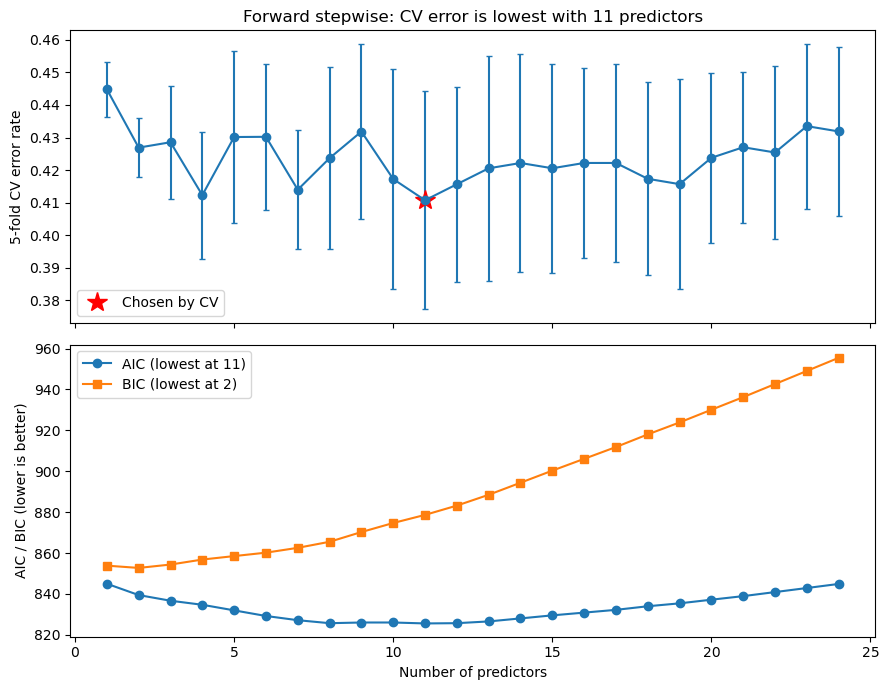

In [9]:
fig, axs = plt.subplots(2, 1, figsize=(9, 7), sharex=True)

axs[0].errorbar(steps.n_predictors, steps.cv_error, yerr=steps.se, marker='o', capsize=2)
axs[0].plot(best_cv.n_predictors, best_cv.cv_error, 'r*', markersize=15, label='Chosen by CV')
axs[0].set(ylabel='5-fold CV error rate',
           title=f'Forward stepwise: CV error is lowest with {best_cv.n_predictors} predictors')
axs[0].legend()

axs[1].plot(steps.n_predictors, steps.aic, marker='o', label=f'AIC (lowest at {best_aic.n_predictors})')
axs[1].plot(steps.n_predictors, steps.bic, marker='s', label=f'BIC (lowest at {best_bic.n_predictors})')
axs[1].set(xlabel='Number of predictors', ylabel='AIC / BIC (lower is better)')
axs[1].legend()

plt.tight_layout()
plt.savefig('reports/forward_cv_plot.png', dpi=150)
plt.show()

**TODO (Thomas):** Which size does CV, AIC and BIC each pick? Do they agree?

## Step 4: Selected model
Odds ratio = e^β: how the odds of being an above-median scorer change for a 1-unit increase in a predictor, holding the others fixed.

In [10]:
final = fit_logit(final_predictors)
cv, se = cv_error(plain_logistic, final_predictors)

print('Predictors:', len(final_predictors))
print('AIC:', round(final.aic, 1))
print('BIC:', round(final.bic, 1))
print('CV error rate:', round(cv, 3))

Predictors: 11
AIC: 825.6
BIC: 878.7
CV error rate: 0.411


In [11]:
table = pd.DataFrame({'coef': final.params,
                      'odds_ratio': np.exp(final.params),
                      'p_value': final.pvalues})
# standardized coefficient = change in log-odds for a 1 SD increase (lets us compare predictors)
table['std_coef'] = table.coef * X_train[final_predictors].std()
table = table.sort_values('std_coef', key=abs, ascending=False)
print(table.round(3))

                 coef  odds_ratio  p_value  std_coef
height_in       0.174       1.190    0.002     0.551
wingspan_in    -0.131       0.877    0.003    -0.502
weight_lb       0.014       1.014    0.045     0.328
skipped_drills  0.712       2.039    0.002     0.273
bench_reps     -0.063       0.939    0.009    -0.250
ncaa_ppg        0.064       1.066    0.008     0.249
sprint_sec     -1.953       0.142    0.030    -0.231
agility_sec    -0.445       0.641    0.037    -0.213
body_fat_pct   -0.068       0.934    0.118    -0.165
ncaa_3p_pct    -0.014       0.986    0.078    -0.157
ncaa_spg        0.250       1.285    0.197     0.130
const           5.947     382.607    0.101       NaN


In [12]:
b = final.params
equation = 'log(p / (1 - p)) = ' + str(round(b['const'], 3))
for var in final_predictors:
    coef = round(b[var], 3)
    if coef >= 0:
        equation += f' + {coef}*{var}'
    else:
        equation += f' - {abs(coef)}*{var}'

print(f'p = P(NBA PPG > {threshold:.2f})')
print(equation)

p = P(NBA PPG > 5.65)
log(p / (1 - p)) = 5.947 + 0.712*skipped_drills - 0.445*agility_sec + 0.064*ncaa_ppg + 0.174*height_in - 0.131*wingspan_in - 1.953*sprint_sec - 0.063*bench_reps - 0.014*ncaa_3p_pct + 0.25*ncaa_spg + 0.014*weight_lb - 0.068*body_fat_pct


**TODO (Thomas):** Interpret at least two odds ratios. Example: "each extra college point per game multiplies the odds of being an above-median NBA scorer by 1.07 (7% higher odds)". For position, name the baseline (Guard).

## Step 5: Test the model once
Predict 1 if the probability is above 0.5. The baseline always predicts the most common training class.

In [13]:
X_test_const = sm.add_constant(X_test[final_predictors], has_constant='add')
prob = final.predict(X_test_const)
pred = (prob > 0.5).astype(int)

accuracy = accuracy_score(y_test, pred)
precision = precision_score(y_test, pred)
recall = recall_score(y_test, pred)
auc = roc_auc_score(y_test, prob)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()

# baseline: always predict the most common class in the training set
majority = 1 if y_train.mean() >= 0.5 else 0
baseline = np.mean(y_test == majority)

print('Test accuracy:', round(accuracy, 3), '| baseline:', round(baseline, 3))
print('Precision:', round(precision, 3), '| Recall:', round(recall, 3), '| AUC:', round(auc, 3))
print('TP:', tp, '| FP:', fp, '| TN:', tn, '| FN:', fn)

Test accuracy: 0.636 | baseline: 0.5
Precision: 0.648 | Recall: 0.597 | AUC: 0.666
TP: 46 | FP: 25 | TN: 52 | FN: 31


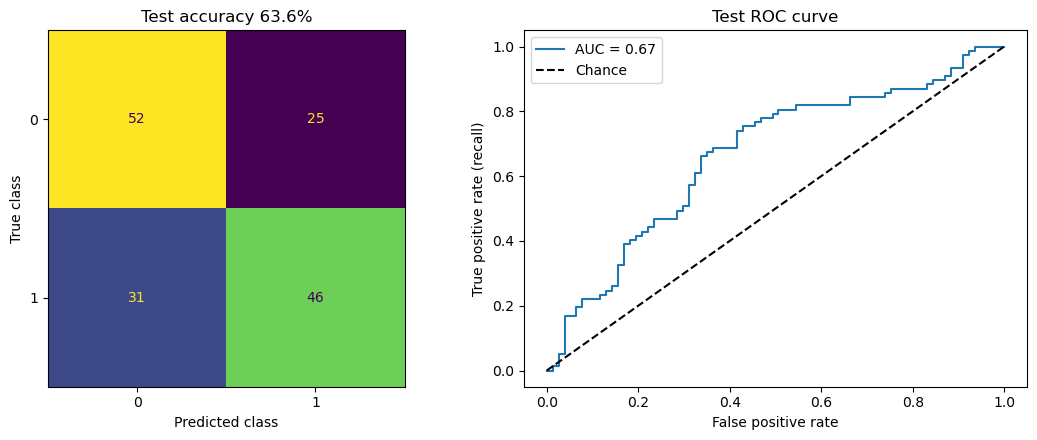

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))

ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=axs[0], colorbar=False)
axs[0].set(xlabel='Predicted class', ylabel='True class', title=f'Test accuracy {accuracy:.1%}')

fpr, tpr, _ = roc_curve(y_test, prob)
axs[1].plot(fpr, tpr, label=f'AUC = {auc:.2f}')
axs[1].plot([0, 1], [0, 1], 'k--', label='Chance')
axs[1].set(xlabel='False positive rate', ylabel='True positive rate (recall)', title='Test ROC curve')
axs[1].legend()

plt.tight_layout()
plt.savefig('reports/forward_test.png', dpi=150)
plt.show()

**TODO (Thomas):** Interpret the AUC in one sentence: "for a random above-median and below-median scorer, the model gives the above-median scorer the higher probability X% of the time." Does the model beat the baseline?

In [15]:
# save results for the group comparison notebook
results = pd.DataFrame([{'member': 'Thomas Ton', 'method': 'Forward stepwise selection',
                         'n_predictors': len(final_predictors), 'predictors': ', '.join(final_predictors),
                         'cv_error': cv, 'aic': final.aic, 'bic': final.bic,
                         'accuracy': accuracy, 'auc': auc, 'precision': precision, 'recall': recall,
                         'tp': tp, 'fp': fp, 'tn': tn, 'fn': fn, 'baseline': baseline}])
results.to_csv('reports/forward_results.csv', index=False)
pd.DataFrame({'fpr': fpr, 'tpr': tpr}).to_csv('reports/forward_roc.csv', index=False)

## Conclusion

**TODO (Thomas):** 3-4 bullets: predictors kept, AIC/BIC/CV error, test accuracy vs baseline, AUC.